In [2]:

print("CODTECH Internship - Task 1")
print("Project: Movie Rating Analysis")
print("Student: Shivani Radder")
print("Status: Project Started Successfully")


CODTECH Internship - Task 1
Project: Movie Rating Analysis
Student: Shivani Radder
Status: Project Started Successfully


In [3]:

# CODTECH Task 1: Data Cleaning

# Check dataset sizes
print("Movies dataset shape:", movies.shape)
print("Ratings dataset shape:", ratings.shape)

# Check missing values
print("\nMissing values in movies:")
print(movies.isnull().sum())

print("\nMissing values in ratings:")
print(ratings.isnull().sum())

# Check duplicate records
print("\nDuplicate movie records:", movies.duplicated().sum())
print("Duplicate rating records:", ratings.duplicated().sum())

# Remove duplicate records
movies = movies.drop_duplicates().copy()
ratings = ratings.drop_duplicates().copy()

# Remove rows with missing essential information
movies = movies.dropna(subset=["movieId", "title", "genres"])
ratings = ratings.dropna(
    subset=["userId", "movieId", "rating", "timestamp"]
)

print("\nCleaning completed!")
print("Movies remaining:", len(movies))
print("Ratings remaining:", len(ratings))

# Display cleaned data
display(movies.head())
display(ratings.head())


NameError: name 'movies' is not defined

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import io
import urllib.request

# Reload the MovieLens dataset
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

response = urllib.request.urlopen(url)
zip_file = zipfile.ZipFile(io.BytesIO(response.read()))

movies = pd.read_csv(
    zip_file.open("ml-latest-small/movies.csv")
)
ratings = pd.read_csv(
    zip_file.open("ml-latest-small/ratings.csv")
)

print("Dataset loaded successfully!")
print("Movies:", len(movies))
print("Ratings:", len(ratings))


Dataset loaded successfully!
Movies: 9742
Ratings: 100836


In [7]:

# STEP 3: DATA CLEANING

print("Missing values in movies:")
print(movies.isnull().sum())

print("\nMissing values in ratings:")
print(ratings.isnull().sum())

print("\nDuplicate movie rows:", movies.duplicated().sum())
print("Duplicate rating rows:", ratings.duplicated().sum())

# Clean the datasets
movies = movies.drop_duplicates().dropna(
    subset=["movieId", "title", "genres"]
).copy()

ratings = ratings.drop_duplicates().dropna(
    subset=["userId", "movieId", "rating", "timestamp"]
).copy()

print("\nData cleaning completed!")
print("Movies remaining:", len(movies))
print("Ratings remaining:", len(ratings))


Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Duplicate movie rows: 0
Duplicate rating rows: 0

Data cleaning completed!
Movies remaining: 9742
Ratings remaining: 100836


In [8]:

# STEP 4: MOVIE RATING ANALYSIS

movie_summary = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    number_of_ratings=("rating", "count")
).reset_index()

movie_summary = movie_summary.merge(
    movies[["movieId", "title"]],
    on="movieId",
    how="left"
)

movie_summary["average_rating"] = (
    movie_summary["average_rating"].round(2)
)

print("Total movies:", movies["movieId"].nunique())
print("Total ratings:", len(ratings))
print("Unique users:", ratings["userId"].nunique())
print("Overall average rating:", round(ratings["rating"].mean(), 2))

print("\nTOP 10 MOST-RATED MOVIES")
display(
    movie_summary.sort_values(
        "number_of_ratings", ascending=False
    ).head(10)
)

print("\nTOP 10 HIGHLY-RATED MOVIES")
display(
    movie_summary[movie_summary["number_of_ratings"] >= 50]
    .sort_values("average_rating", ascending=False)
    .head(10)
)


Total movies: 9742
Total ratings: 100836
Unique users: 610
Overall average rating: 3.5

TOP 10 MOST-RATED MOVIES


,movieId,average_rating,number_of_ratings,title
314,356,4.16,329,Forrest Gump (1994)
277,318,4.43,317,"Shawshank Redemption, The (1994)"
257,296,4.20,307,Pulp Fiction (1994)
510,593,4.16,279,"Silence of the Lambs, The (1991)"
1938,2571,4.19,278,"Matrix, The (1999)"
224,260,4.23,251,Star Wars: Episode IV - A New Hope (1977)
418,480,3.75,238,Jurassic Park (1993)
97,110,4.03,237,Braveheart (1995)
507,589,3.97,224,Terminator 2: Judgment Day (1991)
461,527,4.22,220,Schindler's List (1993)



TOP 10 HIGHLY-RATED MOVIES


,movieId,average_rating,number_of_ratings,title
277,318,4.43,317,"Shawshank Redemption, The (1994)"
659,858,4.29,192,"Godfather, The (1972)"
974,1276,4.27,57,Cool Hand Luke (1967)
2224,2959,4.27,218,Fight Club (1999)
602,750,4.27,97,Dr. Strangelove or: How I Learned to Stop Worr...
686,904,4.26,84,Rear Window (1954)
921,1221,4.26,129,"Godfather: Part II, The (1974)"
913,1213,4.25,126,Goodfellas (1990)
6298,48516,4.25,107,"Departed, The (2006)"
6693,58559,4.24,149,"Dark Knight, The (2008)"


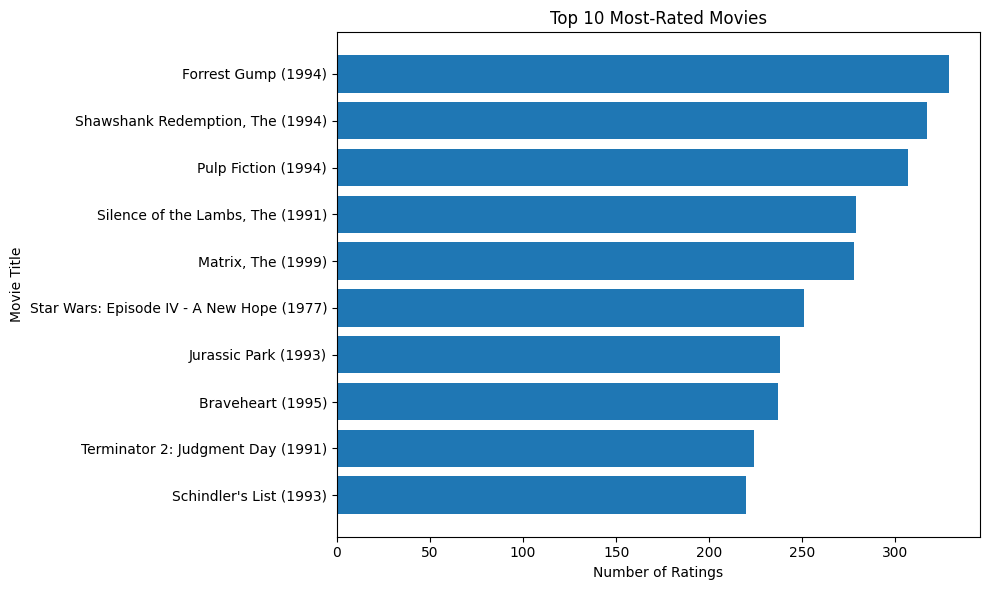

In [9]:

top_movies = movie_summary.nlargest(
    10, "number_of_ratings"
).sort_values("number_of_ratings")

plt.figure(figsize=(10, 6))
plt.barh(
    top_movies["title"],
    top_movies["number_of_ratings"]
)
plt.xlabel("Number of Ratings")
plt.ylabel("Movie Title")
plt.title("Top 10 Most-Rated Movies")
plt.tight_layout()
plt.show()


Number of movies in each genre:


,Movie Count
genres,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


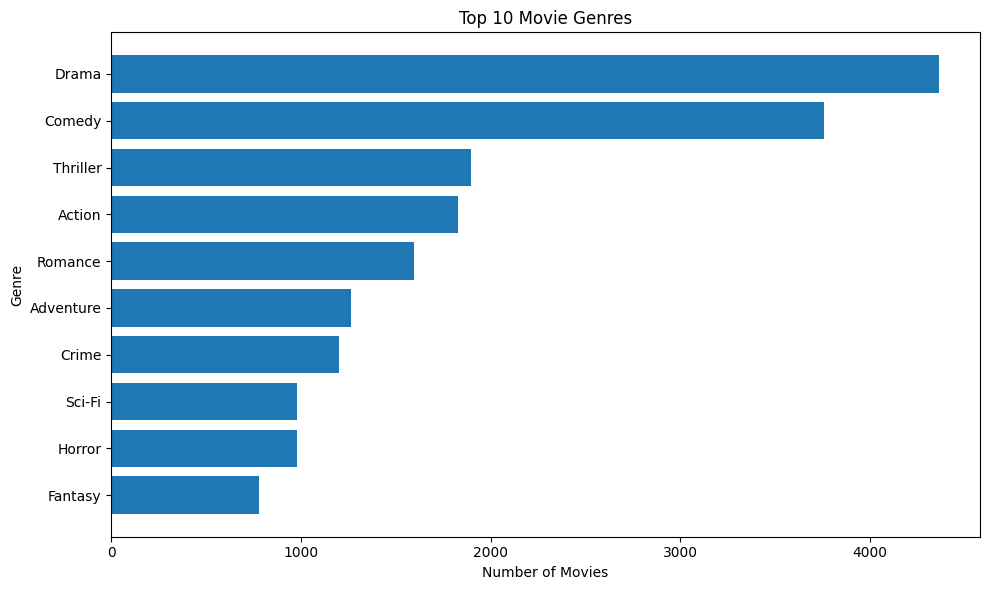

In [10]:

# STEP 6: MOVIE GENRE ANALYSIS

# Split movies that have multiple genres
genre_data = movies[["movieId", "genres"]].copy()
genre_data["genres"] = genre_data["genres"].str.split("|")
genre_data = genre_data.explode("genres")

# Count movies in each genre
genre_counts = genre_data["genres"].value_counts()

print("Number of movies in each genre:")
display(genre_counts.to_frame(name="Movie Count"))

# Plot top 10 genres
top_genres = genre_counts.drop(
    labels=["(no genres listed)"], errors="ignore"
).head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_genres.index, top_genres.values)
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.title("Top 10 Movie Genres")
plt.tight_layout()
plt.show()


In [11]:

# STEP 7: AVERAGE RATING BY GENRE

genre_ratings = ratings.merge(
    movies[["movieId", "genres"]],
    on="movieId",
    how="inner"
)

genre_ratings["genres"] = genre_ratings["genres"].str.split("|")
genre_ratings = genre_ratings.explode("genres")

genre_summary = genre_ratings.groupby("genres").agg(
    average_rating=("rating", "mean"),
    total_ratings=("rating", "count")
).reset_index()

genre_summary["average_rating"] = (
    genre_summary["average_rating"].round(2)
)

print("Average ratings by genre:")
display(
    genre_summary.sort_values(
        "average_rating", ascending=False
    )
)


Average ratings by genre:


,genres,average_rating,total_ratings
10,Film-Noir,3.92,870
18,War,3.81,4859
7,Documentary,3.80,1219
8,Drama,3.66,41928
6,Crime,3.66,16681
14,Mystery,3.63,7674
3,Animation,3.63,6988
12,IMAX,3.62,4145
19,Western,3.58,1930
13,Musical,3.56,4138


# CODTECH Internship — Task 1: Movie Rating Analysis

## Objective
To analyze movie ratings and genres to understand audience preferences and identify popular movies.

## Dataset
MovieLens Small dataset, containing movie titles, genres, user ratings, and timestamps.

## Tools Used
- Python
- Pandas
- Matplotlib
- Google Colab

## Methodology
1. Loaded the movie and ratings datasets.
2. Checked for missing values and duplicate records.
3. Cleaned the data.
4. Calculated average ratings and number of ratings per movie.
5. Identified the most-rated and highly-rated movies.
6. Analyzed movie genres and their average ratings.
7. Created charts to visualize the results.

## Conclusion
This project demonstrates how Python can be used to clean, analyze, and visualize movie-rating data. The analysis helps identify movies that receive the most ratings, compare average movie ratings, and explore the distribution and ratings of different genres.

The results are based on the MovieLens dataset and reflect the ratings available in that dataset.
